<>:27: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:27: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/f9/tdjvw_7s3p16fd0k5csv6xk40000gn/T/ipykernel_84923/2315183160.py:27: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  df = pd.read_csv('seeds_dataset.csv', sep='\s+', names=col_names, header=None)


Overview of Dataset
        area  perimeter  compactness  length_kernel  width_kernel  \
0   15.2600    14.8400       0.8710         5.7630        3.3120   
1   14.8800    14.5700       0.8811         5.5540        3.3330   
2   14.2900    14.0900       0.9050         5.2910        3.3370   
3   13.8400    13.9400       0.8955         5.3240        3.3790   
4   16.1400    14.9900       0.9034         5.6580        3.5620   
..      ...        ...          ...            ...           ...   
205 12.1900    13.2000       0.8783         5.1370        2.9810   
206 11.2300    12.8800       0.8511         5.1400        2.7950   
207 13.2000    13.6600       0.8883         5.2360        3.2320   
208 11.8400    13.2100       0.8521         5.1750        2.8360   
209 12.3000    13.3400       0.8684         5.2430        2.9740   

     asymmetry_coefficient  length_kernel_groove  class  
0                   2.2210                5.2200      1  
1                   1.0180                4.95

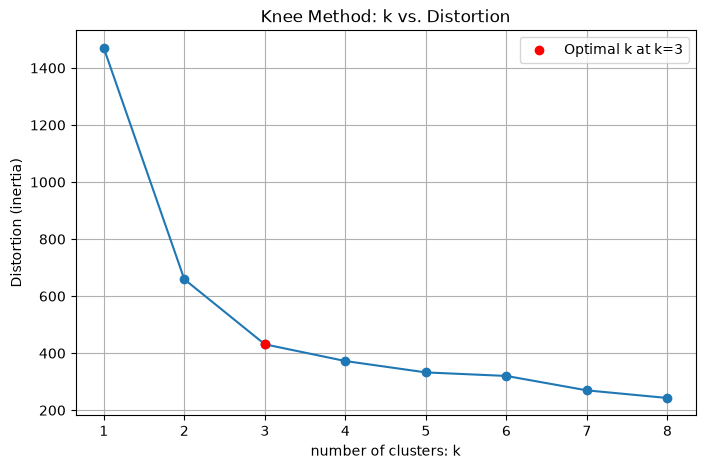


Optimal k identified: 3


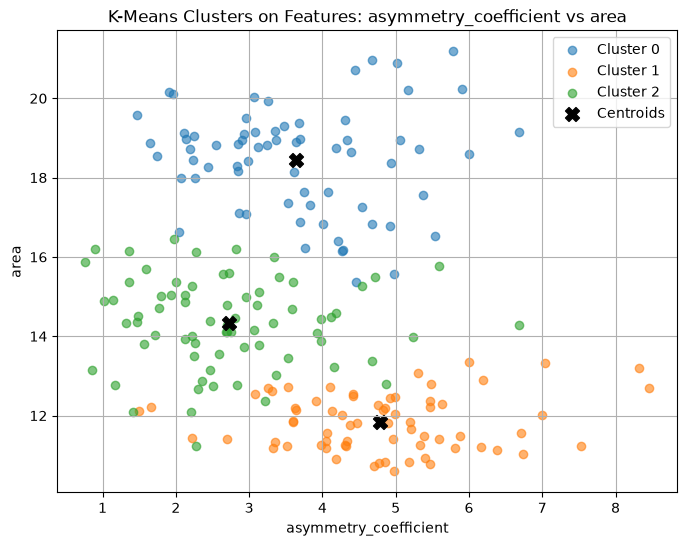


Rerunning k-means clustering with optimal k=3...
Plotting the cluster distribution with selected features: asymmetry_coefficient and area...

Observations:
The clusters show clear vertical separation along the y axis (area), with Cluster 0 occupying the upper 
region, Cluster 1 in the lower region, and Cluster 2 in the middle.
There are noticeable horizontal overlap across all clusters on the x axis (asymmetry coefficient), suggesting
that area is a stronger indicator of cluster membership compared to asymmetry coefficient.
The centroids are close to the densest region within each cluster, showing effective convergence and
strong representativeness of the underlying data distribution, with no visible skewness or misalignment.
There is some boundary overlap, particular between Cluster 1 and Cluster 2, which may indicate grouping
ambiguity or br attributed to variation in other features not shown in the current plot.


Cluster Centroids and Assigned Class Label
      area  perimeter  co

In [ ]:
import sys
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import random
import matplotlib.pyplot as plt
from kneed import KneeLocator
from scipy.spatial.distance import cdist

# ANSI escape code for output formatting
BOLD = "\033[1m" if "idlelib" not in sys.modules else ""
RESET = "\033[0m" if "idlelib" not in sys.modules else ""

# set global decimal display format
pd.set_option('display.float_format', '{:.4f}'.format)


# load dataset
col_names = ['area', 'perimeter', 'compactness', 'length_kernel', 'width_kernel',
            'asymmetry_coefficient', 'length_kernel_groove',
            'class']  # Class Label : Kama: 1, Rosa: 2, Canadian: 3

df = pd.read_csv('seeds_dataset.csv', sep='\s+', names=col_names, header=None)

pd.set_option('display.max_columns', None)
print(f'{BOLD}Overview of Dataset{RESET}\n', df)


"""
Select 2 class labels based on buid last digit, split dataset 50/50
implement SVM with linear, Gaussian, and polynomial kernels
compute the accuracy and confusion matrix metrics for each kernel
"""
# determine the selected class labels based on BUID
buid_last_digit = 3
R = buid_last_digit % 3

if R == 0:
    neg_class, pos_class = 1, 2
elif R == 1:
    neg_class, pos_class = 2, 3
else:
    neg_class, pos_class = 1, 3

print(f'The selected class labels based on my BUID last digit (3) are:'
      f'\nNegative class: {neg_class}, Positive class: {pos_class}')

# df with selected classes
df_svm = df[df['class'].isin([neg_class, pos_class])].copy()

# re-encode class labels for model interpretability
df_svm['class'] = df_svm['class'].map({neg_class: 0, pos_class: 1})

# split df
seed = 42
X_svm = df_svm.drop('class', axis=1)
y_svm = df_svm['class']
X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(X_svm, y_svm, test_size=0.5, random_state=seed)


def evaluate_metrics(model_name, y_test, y_pred, verbose=0):
    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    tn, fp, fn, tp = cm.ravel()

    tpr = tp / (tp + fn) if (tp + fn) else 0
    tnr = tn / (tn + fp) if (tn + fp) else 0

    cm_result = pd.DataFrame([{'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn,
                               'accuracy': acc, 'TPR': tpr, 'TNR': tnr}], index=[model_name])

    if verbose < 2:
        header = f'{BOLD}{model_name} Model{RESET}\n' if verbose == 0 else ''
        print(f'{header}'
              f'Accuracy: {acc:.4f}\n'
              f'Confusion Matrix Metrics:\n{cm_result}\n')
    return cm_result


def build_svm(model_name, kernel_type, X_train, X_test, y_train, y_test, degree=None, verbose=0):
    assert isinstance(model_name, str), "model_name must be a string"
    assert kernel_type in ['linear', 'rbf', 'poly'], "kernel_type must be 'linear', 'rbf', or 'poly'"

    if kernel_type == 'poly':
        model = SVC(kernel=kernel_type, degree=degree)
    else:
        model = SVC(kernel=kernel_type)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # evaluate model
    cm_result = evaluate_metrics(model_name, y_test, y_pred, verbose)

    return cm_result


linear_result = build_svm('linear SVM', 'linear', X_train_svm, X_test_svm, y_train_svm, y_test_svm)
gaussian_result = build_svm('Gaussian SVM', 'rbf', X_train_svm, X_test_svm, y_train_svm, y_test_svm)
poly_result = build_svm('Polynomial SVM', 'poly', X_train_svm, X_test_svm, y_train_svm, y_test_svm, degree=3)


"""
Selected model: logistic regression classifier, compute its accuracy and confusion matrix metrics
compare with the three SVM models
"""
# logistic regression
logreg = LogisticRegression()
logreg.fit(X_train_svm, y_train_svm)
y_pred_logreg = logreg.predict(X_test_svm)

logreg_result = evaluate_metrics('Logistic Regression', y_test_svm, y_pred_logreg)


compare_df = pd.concat([linear_result, gaussian_result, poly_result, logreg_result])

print(f'{BOLD}\nModel Comparison\n{RESET}{compare_df}\n')

print(f'{BOLD}Observations:{RESET}'
      'Gaussian SVM, Polynomial SVM, and Logistic Regression all achieved the highest 0.9429 accuracy, indicating\n'
      'strong overall generalization.\n'
      'Linear SVM has a slightly lower accuracy of 0.9286, with the highest TPR at 0.9355 and the lowest TNR at \n'
      '0.9231 among all models.  These suggest that the model tends to misclassify more negative cases, and the \n'
      'separation between classes is not perfectly linear, which can be attributed to more complex, nonlinear \n'
      'patterns in the feature space.\n'
      'Gaussian SVM achieves the highest TNR of 0.9744 but the lowest TPR of 0.9032, suggesting it is a more \n'
      'conservative model, i.e. it is effective at avoiding false positives but at the cost of misclassifying some\n'
      'true positives. This is suitable for scenarios where false negatives are costly.\n'
      'Polynomial SVM and Logistic Regression are the most balanced models, both achieving TPR of 0.9355 and TNR of\n'
      '0.9487, which is suitable for scenarios where both error types are equally important.')


"""
Use the original dataset w/ 3 class labels, find the optimal k for k-means clustering
rerun the kmeans w/ optimal k, and assign cluster label using majority voting of the class labels
build a classifier based on euclidean distance to the nearest cluster centroids, compute accuracy
compute the accuracy and confusion matrix metrics for the new classifier with the same 2 classes in SVM
"""
X_kmeans = df.drop('class', axis=1)
scaler = StandardScaler()
X_kmeans_scaled = scaler.fit_transform(X_kmeans)


# find optimal k, knee method
k_values = range(1, 9)
inertia_list = []

print(f"{'k':<4} distortion")
for k in k_values:
    kmeans_classifier = KMeans(n_clusters=k)
    y_kmeans = kmeans_classifier.fit_predict(X_kmeans_scaled)
    inertia = kmeans_classifier.inertia_
    inertia_list.append(inertia)
    print(f'{k:<4} {inertia:>5.4f}')

# use KneeLocator to find the optimal k
knee = KneeLocator(k_values, inertia_list, curve="convex", direction="decreasing")
optimal_k = knee.elbow

# plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, 9), inertia_list, marker='o')
plt.scatter(optimal_k, inertia_list[optimal_k - 1], color='red', zorder=5, label=f'Optimal k at k={optimal_k}')
plt.xlabel('number of clusters: k')
plt.ylabel('Distortion (inertia)')
plt.title('Knee Method: k vs. Distortion')
plt.legend()
plt.grid(True)
plt.show()

print(f'\nOptimal k identified: {optimal_k}')

# rerun k-means with optimal k
kmeans = KMeans(n_clusters=optimal_k, random_state=seed)
df_kmeans = df.copy()
df_kmeans['cluster'] = kmeans.fit_predict(X_kmeans_scaled)

# randomly select 2 features
random.seed(seed)
features = random.sample(col_names[:-1], 2)  # exclude 'class'
fi, fj = features

# reverse-scale the centroids
centroids_scaled = kmeans.cluster_centers_
centroids = pd.DataFrame(scaler.inverse_transform(centroids_scaled), columns=X_kmeans.columns)

# plot the cluster distribution w/ selected 2 features
plt.figure(figsize=(8,6))
for cluster in range(optimal_k):
    cluster_points = df_kmeans[df_kmeans['cluster'] == cluster]
    plt.scatter(cluster_points[fi], cluster_points[fj], label=f'Cluster {cluster}', alpha=0.6)
plt.scatter(centroids[fi], centroids[fj], c='black', marker='X', s=100, label='Centroids')
plt.xlabel(fi)
plt.ylabel(fj)
plt.title(f'K-Means Clusters on Features: {fi} vs {fj}')
plt.legend()
plt.grid(True)
plt.show()

print(f'\nRerunning k-means clustering with optimal k={optimal_k}...'
      f'\nPlotting the cluster distribution with selected features: {fi} and {fj}...')

print(f'\n{BOLD}Observations:{RESET}'
      f'\nThe clusters show clear vertical separation along the y axis (area), with Cluster 0 occupying the upper '
      f'\nregion, Cluster 1 in the lower region, and Cluster 2 in the middle.'
      f'\nThere are noticeable horizontal overlap across all clusters on the x axis (asymmetry coefficient), suggesting'
      f'\nthat area is a stronger indicator of cluster membership compared to asymmetry coefficient.'
      f'\nThe centroids are close to the densest region within each cluster, showing effective convergence and'
      f'\nstrong representativeness of the underlying data distribution, with no visible skewness or misalignment.'
      f'\nThere is some boundary overlap, particular between Cluster 1 and Cluster 2, which may indicate grouping'
      f'\nambiguity or br attributed to variation in other features not shown in the current plot.')


# assign cluster label based on majority voting
majority_class = {}

for cluster in range(optimal_k):
    cluster_mode = df_kmeans[df_kmeans['cluster'] == cluster]['class'].mode()

    if len(cluster_mode) > 1:
        print(f'Cluster {cluster} has multiple majority classes: {list(cluster_mode.values)}, '
              f'default assigning{cluster_mode.iloc[0]}')

    majority_class[cluster] = cluster_mode.iloc[0]

df_kmeans['cluster_label'] = df_kmeans['cluster'].map(majority_class)
centroids['assigned_label'] = centroids.index.map(majority_class)

print(f'\n\n{BOLD}Cluster Centroids and Assigned Class Label{RESET}\n', centroids)


# assign label based on euclidean distance to the nearest cluster centroids
distances = cdist(X_kmeans.values, centroids.iloc[:, :-1].values, metric='euclidean')

nc_centroid = distances.argmin(axis=1)
df_kmeans['nc_label'] = centroids['assigned_label'].iloc[nc_centroid].values

acc_nc = accuracy_score(df_kmeans['class'], df_kmeans['nc_label'])
print(f'\n\n{BOLD}Nearest Centroid Classifier:{RESET}'
      f'\nAccuracy: {acc_nc:.4f}\n')


# assess the performance metrics using the same 2 classes in SVM models
nc2_df = df[df['class'].isin([neg_class, pos_class])].copy()
nc2_cluster_centroids = centroids[centroids['assigned_label'].isin([pos_class, neg_class])]

nc2_distances= cdist(nc2_df.drop(columns='class').values, nc2_cluster_centroids.iloc[:, :-1].values, metric='euclidean')
nc2_centroid = nc2_distances.argmin(axis=1)
nc2_df['nc_label'] = nc2_cluster_centroids['assigned_label'].iloc[nc2_centroid].values

# map to positive and negative label
nc2_df['class'] = nc2_df['class'].map({neg_class: 0, pos_class: 1})
nc2_df['nc_label'] = nc2_df['nc_label'].map({neg_class: 0, pos_class: 1})

print(f'\n{BOLD}Nearest Centroid Classifier with two classes:{RESET}')
nc_result = evaluate_metrics('NC Classifier', nc2_df['class'], nc2_df['nc_label'], verbose=1)

# compare with other classifiers
compare_df = pd.concat([compare_df, nc_result])
print(f'\n{BOLD}Comparison of all Classifiers{RESET}\n', compare_df)

print(f'\n{BOLD}Observations:{RESET}'
      'The Nearest Centroid-based Classifier achieved an accuracy rate of 0.9429, matching the highest accuracy \n'
      'shared among Gaussian SVM, Polynomial SVM, and Logistic Regression.  Its TNR of 0.9714 ranked the second, \n'
      "slightly lower than Gaussian SVM's 0.9744 TNR, and yet still reflects strong specificity. The 0.9143 TPR ranks\n"
      "in the middle among all models, indicating moderate sensitivity and slight bias toward negative classes.\n"
      "Overall, despite the simplicity in its mechanism, the NC Classifier demonstrates impressive performance that\n"
      "is comparable to more complex models such as SVM and logistic regression, indicating that the underlying class\n"
      "in the dataset show distinct feature characteristics and are well-separated in the Euclidean space.")